# E10 · Uncertainty and location of the count gains

Protocol addendum: [`protocolo_revision.md`](../protocolo_revision.md). Written after E1–E8, in response to external feedback; every result here is exploratory. Negative changes favour the first arm; intervals are 95% whole-season bootstrap intervals (20,000 draws, seeds paired).

Loss: absolute error of the published count (model mean blended with persistence). Estimand: pooled relative change in mean absolute error (ratio of summed absolute errors per seed, median over seeds). In the output columns `mae_a` and `mae_b` are the pooled MAE of each arm.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import experiments as ex

RES = c.OUTPUT / "resultados"
FIG = STUDY / "figures"
OTHER = tuple(s for s in c.SEASONS if s not in c.DECISION_SEASONS)
read_base = lambda name: pd.read_csv(c.OUTPUT / name, dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])

import e8
import onset_analysis as oa

In [2]:
inputs, _ = c.load_inputs(validate=False)
labels = inputs["etiquetas"]
short = {name: c.read_arm(arm, columns=ex.PRED_COLUMNS) for name, arm in (("climate", "b3_obs"), ("no climate", "historia_geo"))}
LONG = ["semilla", "bloque", "horizonte", "ubigeo", "semana_inicio", "origen_cierre", "casos_Dengue", "brote",
        "umbral_brote_casos", "persistencia", "mu_modelo", "conteo_publicado", "alpha_usada", "probabilidad_cruda",
        "probabilidad_calibrada"]
long = {name: c.read_arm(arm, columns=LONG, folder=e8.OUT_DIR) for name, arm in (("climate", "b3_obs_largo"), ("no climate", "historia_geo_largo"))}
base = {"short": read_base("baselines.csv.gz"), "long": read_base("baselines_largo.csv.gz")}
for frame in (*short.values(), base["short"]):
    frame["estado"] = oa.origin_state(frame, labels)

In [3]:
def count_contrasts(frames, persistence, group, seasons=c.SEASONS):
    s = {k: ex.sae(v, seasons=seasons) for k, v in frames.items()}
    s["persistence"] = ex.sae(persistence, count="persistencia", seasons=seasons)
    rows = [ex.contrast(s[a], s[b], value="sae").assign(comparison=f"{a} vs {b}")
            for a, b in (("climate", "no climate"), ("climate", "persistence"), ("no climate", "persistence"))]
    return pd.concat(rows).rename(columns={"brier_a": "mae_a", "brier_b": "mae_b"}).assign(group=group)

rows = [count_contrasts(short, base["short"], "18 seasons"), count_contrasts(long, base["long"], "18 seasons")]
for group, seasons in (("6 development seasons", c.DECISION_SEASONS), ("12 other seasons", OTHER)):
    rows.append(count_contrasts(short, base["short"], group, seasons))
for state in ("quiet", "active"):
    rows.append(count_contrasts({k: v[v.estado.eq(state)] for k, v in short.items()},
                                base["short"][base["short"].estado.eq(state)], f"origin {state}"))
counts = pd.concat(rows)[["group", "comparison", "horizonte", "temporadas", "mae_a", "mae_b", "cambio_agrupado_%",
                          "ic95_agrupado", "cambio_igual_peso_%", "temporadas_a_mejor"]]
counts.to_csv(RES / "e10_conteos_incertidumbre.csv", index=False)
counts[counts.comparison.eq("climate vs no climate")].round(3)

,group,comparison,horizonte,temporadas,mae_a,mae_b,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,temporadas_a_mejor
0,18 seasons,climate vs no climate,2,18,1.728,1.798,-3.983,"(-10.31, 1.16)",-1.011,9
1,18 seasons,climate vs no climate,3,18,2.172,2.320,-6.568,"(-16.27, 1.67)",-2.180,11
2,18 seasons,climate vs no climate,4,18,2.552,2.780,-8.207,"(-21.87, 2.87)",-2.469,11
0,18 seasons,climate vs no climate,8,18,3.597,3.756,-4.834,"(-15.17, 5.13)",-2.516,10
1,18 seasons,climate vs no climate,12,18,4.023,4.515,-10.285,"(-25.77, 3.99)",-5.553,10
0,6 development seasons,climate vs no climate,2,6,2.729,2.776,-1.428,"(-3.19, 2.39)",-0.215,2
1,6 development seasons,climate vs no climate,3,6,3.360,3.453,-2.563,"(-6.01, 2.76)",-1.088,3
2,6 development seasons,climate vs no climate,4,6,3.916,3.988,-1.596,"(-7.52, 5.38)",-0.007,3
0,12 other seasons,climate vs no climate,2,12,1.226,1.310,-6.692,"(-15.92, 1.86)",-1.408,7
1,12 other seasons,climate vs no climate,3,12,1.577,1.754,-10.133,"(-24.18, 2.92)",-2.725,8


In [4]:
counts[counts.comparison.ne("climate vs no climate") & counts.group.eq("18 seasons")].round(3)

,group,comparison,horizonte,temporadas,mae_a,mae_b,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,temporadas_a_mejor
0,18 seasons,climate vs persistence,2,18,1.728,1.918,-9.886,"(-15.35, 0.33)",21.044,10
1,18 seasons,climate vs persistence,3,18,2.172,2.507,-13.339,"(-20.1, -1.19)",27.545,10
2,18 seasons,climate vs persistence,4,18,2.552,3.003,-15.022,"(-22.29, -1.57)",37.477,10
0,18 seasons,no climate vs persistence,2,18,1.798,1.918,-6.260,"(-13.63, 8.35)",21.809,8
1,18 seasons,no climate vs persistence,3,18,2.320,2.507,-7.450,"(-17.73, 13.69)",29.737,8
2,18 seasons,no climate vs persistence,4,18,2.780,3.003,-7.452,"(-20.68, 20.6)",40.383,9
0,18 seasons,climate vs persistence,8,18,3.597,4.551,-20.960,"(-31.02, 3.91)",105.433,8
1,18 seasons,climate vs persistence,12,18,4.023,5.434,-25.978,"(-33.49, -0.56)",126.995,10
0,18 seasons,no climate vs persistence,8,18,3.756,4.551,-17.488,"(-30.78, 12.48)",108.007,9
1,18 seasons,no climate vs persistence,12,18,4.515,5.434,-16.916,"(-31.42, 11.0)",128.502,8


## Leave one season out

The season whose omission changes the result most is shown with its interval (chosen after seeing the leave-one-out table, so descriptive).

In [5]:
loo = pd.concat([ex.leave_one_out(ex.sae(f["climate"]), ex.sae(f["no climate"]), value="sae") for f in (short, long)])
loo.to_csv(RES / "e10_conteos_sin_una_temporada.csv", index=False)
print(loo.groupby("horizonte")["cambio_agrupado_%"].agg(["min", "max"]).round(2))
most = int(loo.loc[loo.groupby("horizonte")["cambio_agrupado_%"].idxmax(), "omitida"].mode()[0])
kept = tuple(s for s in c.SEASONS if s != most)
without = pd.concat([count_contrasts(short, base["short"], f"without {most}", kept),
                     count_contrasts(long, base["long"], f"without {most}", kept)])
without.to_csv(RES / "e10_conteos_sin_temporada_dominante.csv", index=False)
print("season whose omission removes most of the gain:", most)
without[without.comparison.eq("climate vs no climate")][["group", "horizonte", "mae_a", "mae_b", "cambio_agrupado_%",
                                                      "ic95_agrupado", "temporadas_a_mejor"]].round(3)

             min   max
horizonte             
2          -5.19 -0.69
3          -8.95 -1.06
4         -11.25 -0.17
8          -8.19  0.68
12        -13.75  0.64


season whose omission removes most of the gain: 2024


,group,horizonte,mae_a,mae_b,cambio_agrupado_%,ic95_agrupado,temporadas_a_mejor
0,without 2024,2,1.551,1.562,-0.690,"(-2.48, 1.6)",8
1,without 2024,3,1.947,1.968,-1.063,"(-4.4, 2.42)",10
2,without 2024,4,2.274,2.279,-0.172,"(-5.09, 3.88)",10
0,without 2024,8,3.099,3.065,0.675,"(-6.36, 6.66)",9
1,without 2024,12,3.470,3.447,0.643,"(-7.0, 5.26)",9


## Where the count gains occur: by season

In [6]:
per = []
for label, frames in (("short", short), ("long", long)):
    a, b = ex.sae(frames["climate"]), ex.sae(frames["no climate"])
    m = a.merge(b, on=["semilla", "temporada", "horizonte", "n"], suffixes=("_climate", "_none"))
    m["cambio_%"] = 100 * (m.sae_climate / m.sae_none - 1)
    per.append(m.groupby(["temporada", "horizonte"]).agg(**{"cambio_%": ("cambio_%", "median"),
               "mae_climate": ("sae_climate", lambda s: np.median(s)), "mae_none": ("sae_none", "median"), "n": ("n", "first")}).reset_index())
per = pd.concat(per)
per["mae_climate"], per["mae_none"] = per.mae_climate / per.n, per.mae_none / per.n
cases = (ex.seasons_only(short["no climate"]).query("semilla == 17 and horizonte == 2").groupby("temporada").casos_Dengue.sum().rename("casos"))
per = per.merge(cases, on="temporada")
per.to_csv(RES / "e10_conteos_por_temporada.csv", index=False)
per[per.horizonte.eq(4)].round(2)

,temporada,horizonte,cambio_%,mae_climate,mae_none,n,casos
2,2009.0,4,-5.43,1.30,1.38,3445,4241
5,2010.0,4,-0.47,2.25,2.24,3380,8447
8,2011.0,4,-20.94,0.19,0.24,3380,141
11,2012.0,4,-2.70,0.33,0.34,3380,1098
14,2013.0,4,-2.86,0.67,0.70,3380,2095
17,2014.0,4,-4.20,0.46,0.48,3380,2190
20,2015.0,4,2.18,3.30,3.23,3445,17058
23,2016.0,4,9.91,1.96,1.79,3380,6586
26,2017.0,4,5.16,9.90,9.38,3380,42259
29,2018.0,4,-15.72,0.49,0.58,3380,872


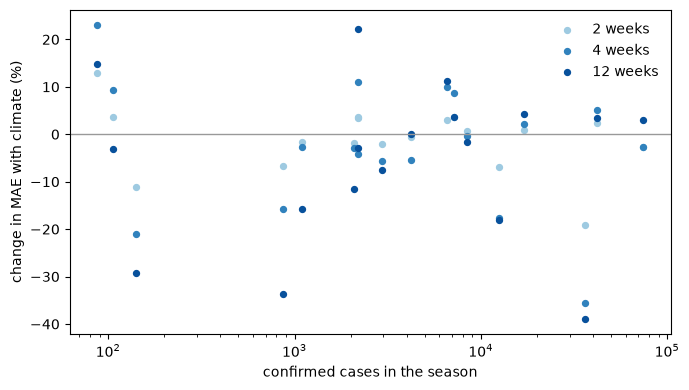

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for h, color in ((2, "#9ecae1"), (4, "#3182bd"), (12, "#08519c")):
    d = per[per.horizonte.eq(h)]
    ax.scatter(d.casos, d["cambio_%"], color=color, label=f"{h} weeks", s=18)
ax.axhline(0, color="0.6", lw=1)
ax.set_xscale("log")
ax.set_xlabel("confirmed cases in the season")
ax.set_ylabel("change in MAE with climate (%)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "e10_conteos_por_temporada.png", dpi=150)

## Reading

- Climate changed the pooled MAE of the published count by −3.98%, −6.57% and −8.21% at two to four weeks and by −4.83% and −10.29% at eight and twelve weeks. Every interval includes zero, and climate had the lower MAE in 9 to 11 of 18 seasons.
- The gain comes from one season. Without 2024 the change is −0.69%, −1.06%, −0.17%, +0.68% and +0.64% (four-week interval −5.09% to +3.88%); in 2024 climate lowered the four-week MAE by 35.5%.
- By origin state, the four-week point estimate was −9.88% where the district was already active and −0.95% where it was quiet (both intervals include zero).
- Against the persistence count, the climate model lowered the four-week MAE by 15.0% (1.6% to 22.3%); the model without climate by 7.5% (interval includes zero).